### Project: Census Income Dataset - Exploratory Data Analysis and Modeling

*  Data: https://archive.ics.uci.edu/dataset/20/census+income
    - Census Income Database - 1994, extraction done by Barry Becker
    - 48842 instances, mix of continuous and discrete    (train=32561, test=16281), it has two datasets, and we will merge them.
    - In dataset, Income is the target value whether a person earns more than $50K or not in a year.

- Data Cleaning and Preparation 
- Exploratory Data Analysis
- Test Statistics
- Regression and Classification
- Predict age based on work-related, demographic, and income features.
- Logistics regression to classify if an observation makes >50K or <=50K yearly.
- Clustering- Advanced Analysis Techniques
- K-Means: Separate the dataset into two clusters (k = 2) based on features like age, education, income, marital_status etc., without telling the model the actual sex labels.

### Dataset
Loading the dataset from current directroy, and merging train and test datasets.

We have total 48,842 instances. It is enough data to handle null values and any outliers in data preparation task. 

In [1339]:
# import important libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [1340]:
# Get the adult_data.csv file
file_adult_data= 'adult_data'
try:
    df_adult_data = pd.read_csv(f'{file_adult_data}.csv', header = None, skipinitialspace=True)
except FileNotFoundError:
    print(f"Error: The file '{file_adult_data}.csv' was not found.")

# Show the records
df_adult_data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [1341]:
# Get the adult_test.csv file
file_adult_test= 'adult_test'
try:
    df_adult_test = pd.read_csv(f'{file_adult_test}.csv', header = None, skiprows = 1, skipinitialspace=True)
except FileNotFoundError:
    print(f"Error: The file '{file_adult_test}.csv' was not found.")

# Show the records
df_adult_test.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
1,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
2,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
3,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K.
4,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K.


In [1342]:
# Merging adult census train and test data
df_census_income = pd.concat([df_adult_data, df_adult_test], ignore_index=True)

In [1343]:
# Column names from UCI site
columns = [ "age", "workclass", "fnlwgt", "education", "education_num",
           "marital_status", "occupation", "relationship", "race", "sex",
           "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
        ]

df_census_income.columns = columns

# Clean target column (test file has a trailing period in labels)
df_census_income["income"] = df_census_income["income"].str.replace(".", "", regex=False).str.strip()
df_census_income.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### Dataset: features description
* **age: Continuous (Discrete)**
* **workclass: Nominal (Categorical)** - Categories with no inherent order (Private, Self-emp, etc.).
* **fnlwgt: Continuous** - Final weight of the record. Basically interpret as the number of people represented by this row
* **education: Ordinal (Categorical)** - Categories with a meaningful order (Preschool < HS-grad < Bachelors < Masters, etc.).
* **education_num: Discrete (Numerical)** - Integer representation of education level.
* **marital_status: Nominal (Categorical)** - Categories with no inherent order (Married, Divorced, etc.).
* **occupation: Nominal (Categorical)** - Job types with no inherent order.
* **relationship: Nominal (Categorical)** - Family role categories without order.
* **race: Nominal (Categorical)** - Ethnic/racial categories without order.
* **sex: Nominal (Categorical)** - Male/Female without order.
* **capital_gain:	Continuous (Ratio)** - Monetary values with meaningful zero.
* **capital_loss: Continuous (Ratio)** - Monetary values with meaningful zero.
* **hours_per_week: Continuous (Ratio)** - Measured hours, can take fractional values in theory.
* **native_country: Nominal (Categorical)** - Country names without order.
* **income: Binary Nominal (Categorical)** - <=50K and >50K



## Data Cleaning and Preparation

Make the dataset accurate, consistent, and ready for analysis and modeling.
- Handle missing values (removal)
- Removing '?'
- Remove duplicates
- Correct data types

In [1344]:
# dataset shape: before data cleaning and preparation
df_census_income.shape

(48841, 15)

In [1345]:
# removing "?" values
df_census_income = df_census_income[~df_census_income.isin(["?"]).any(axis=1)]
df_census_income.shape

(45221, 15)

In [1346]:
# Drop any Nan or None values
df_census_income.dropna(inplace=True)
df_census_income.shape

(45221, 15)

In [1347]:
# Drop duplicate values
df_census_income.drop_duplicates(inplace=True)
df_census_income.shape

(45174, 15)

In [1348]:
# Check any Nan or None values in dataframe
df_census_income.isna().any().any()

False

In [1349]:
# dataset info
df_census_income.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45174 entries, 0 to 48840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45174 non-null  int64 
 1   workclass       45174 non-null  object
 2   fnlwgt          45174 non-null  int64 
 3   education       45174 non-null  object
 4   education_num   45174 non-null  int64 
 5   marital_status  45174 non-null  object
 6   occupation      45174 non-null  object
 7   relationship    45174 non-null  object
 8   race            45174 non-null  object
 9   sex             45174 non-null  object
 10  capital_gain    45174 non-null  int64 
 11  capital_loss    45174 non-null  int64 
 12  hours_per_week  45174 non-null  int64 
 13  native_country  45174 non-null  object
 14  income          45174 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.5+ MB


In [1350]:
# dataset: data types
df_census_income.dtypes.value_counts()

# Count of each category
counts = df_census_income["income"].value_counts()

# Percentage of each category
percentages = df_census_income["income"].value_counts(normalize=True) * 100

# Combine into a single DataFrame for clarity
income_summary = pd.DataFrame({ "Count": counts, "Percentage (%)": percentages.round(2)})

print(income_summary) # dataset is highly imbalance.

        Count  Percentage (%)
income                       
<=50K   33972            75.2
>50K    11202            24.8


In [1351]:
# native_country columns: replace "United-States" with "US".
df_census_income['native_country'] = df_census_income['native_country'].replace('United-States', 'US')

# Create new label: capital_diff
df_census_income["capital_diff"] = df_census_income["capital_gain"] - df_census_income["capital_loss"]

# Save merged dataset to current directory
df_census_income.to_csv("df_census_income_merged.csv", index=False)

In [1352]:
# Summary statistics: Before any transformation and normalization
df_census_income.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_diff
count,45174.000000,4.517400e+04,45174.000000,45174.000000,45174.000000,45174.000000,45174.000000
mean,38.556471,1.897380e+05,10.119383,1102.600677,88.689556,40.942533,1013.911121
std,13.215341,1.056535e+05,2.551726,7510.331212,405.160881,12.007862,7534.242690
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000,-4356.000000
25%,28.000000,1.173922e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783120e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,47.000000,2.379030e+05,13.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000,99999.000000


### Before IQR statistics: Outliers analysis based on data summary statistics , 

age:
- human age rarely >= 90 in working population, it could be a long tail.

education_num: 
- It does not seem an issue, since range 1–16; all are valid education levels.

hours_per_week: 
- It seems extreme, as 1 or 99 hours pe week.

capital_gain:
- It could be outliers, few people have high capital gains.

capital_loss: 
- Likely only a handful of people.

fnlwgt (final weight) tells how many people in the population that record represents. It is not a predictor of income or other outcomes—it’s a sampling weight for survey representativeness. So We may ignore fnlwgt here.

Z-score method is used when we have a partial normal data.

We will use IQR method (Interquartile Range) for skewed and outlier data analysis.


IQR Outlier Summary:
                   Q1    Q3   IQR  Lower Bound  Upper Bound  Outlier Count
age             28.0  47.0  19.0         -0.5         75.5          268.0
education_num    9.0  13.0   4.0          3.0         19.0          290.0
hours_per_week  40.0  45.0   5.0         32.5         52.5        11889.0
capital_diff     0.0   0.0   0.0          0.0          0.0         5930.0
capital_gain     0.0   0.0   0.0          0.0          0.0         3790.0
capital_loss     0.0   0.0   0.0          0.0          0.0         2140.0


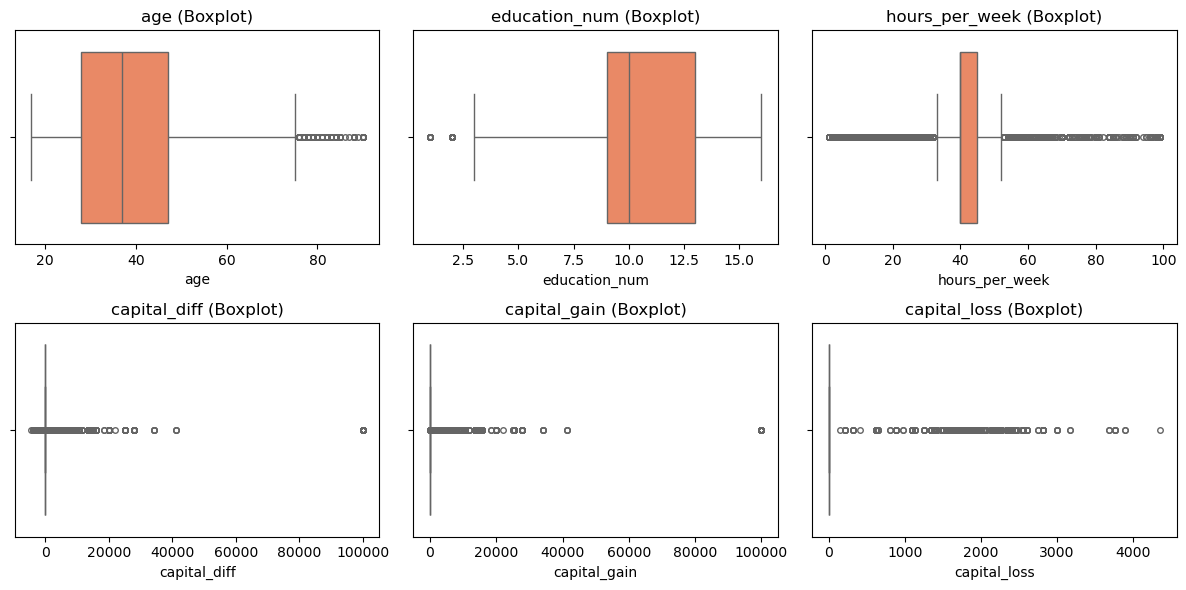

In [1353]:
features = ['age', 'education_num', 'hours_per_week', 'capital_diff', 'capital_gain', 'capital_loss']

# Function to calculate IQR bounds and detect outliers
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return Q1, Q3, IQR, lower_bound, upper_bound, outliers

# store results
iqr_results = {}
for col in features:
    Q1, Q3, IQR, lower, upper, outliers = detect_outliers_iqr(df_census_income, col)
    iqr_results[col] = {'Q1': Q1, 'Q3': Q3, 'IQR': IQR, 'Lower Bound': lower, 'Upper Bound': upper,'Outlier Count': len(outliers) }

# dataframe with IQR summary
iqr_df = pd.DataFrame(iqr_results).T
print("\nIQR Outlier Summary:\n", iqr_df)

# Boxplots 
plt.figure(figsize=(12, 6))
for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df_census_income[col], color='coral', fliersize=4)
    plt.title(f'{col} (Boxplot)')
plt.tight_layout()
plt.show()


### After IQR statistics: Outlier analysis in real life aspects
capital_gain and capital_loss: we will not remove outliers.

    - It contains real economic features, so we are keeping them. Many of these are valid and might be important for predicting income class.

hours_per_week: we will not remove outliers.

    - Outliers# 11,889 rows,  they might be important for predicting income, removing hours_per_week outlier could reduce the dataset significnatly. We add part-time, full-time and over-time as values for new features.

education_num and age: we will not remove outliers.

    - 1 to 16 are valid education level. If it was 0 or 100 we would have considered to remove them.

age: We can remove age outlier. 

**There are few extreme numbers but they all are valid in real life and economically. since they all contribute in tax some way to govt and contirbuting in economy.**

**We will use Min-Max scaling, and Log & SQRT normalization to squeeze any outlier.**




In [1354]:
# Removing "Age" outliers
df_census_income_ot = df_census_income.copy()

num_col = ["age"]
for col in num_col:
    Q1 = df_census_income_ot[col].quantile(0.25)
    Q3 = df_census_income_ot[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Keep only rows within the bounds
    df_census_income_ot = df_census_income_ot[(df_census_income_ot[col] >= lower_bound) & (df_census_income_ot[col] <= upper_bound)]

print(f"Original shape: {df_census_income.shape}")
print(f"After removing outliers: {df_census_income_ot.shape}")

Original shape: (45174, 16)
After removing outliers: (44906, 16)


In [1356]:
# Adding work_time_category features: part_time < 30,  30<= full_time <=40 ; over_time > 40

df_census_income_ot['work_time_category'] = pd.cut(
    df_census_income_ot['hours_per_week'],
    bins=[0, 30, 40, float('inf')],
    labels=['part_time', 'full_time', 'over_time'],
    right=True,  # includes the upper bound in each bin
    include_lowest=True
)

# Numeric column list for programing
numeric_cols = ["age", "fnlwgt", "education_num", "capital_diff", "hours_per_week"]

# categorical column list for programing 
categorical_cols = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country", "income", "work_time_category"]

df_census_income_ot.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,capital_diff,work_time_category
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,US,<=50K,2174,full_time
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,US,<=50K,0,part_time
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,US,<=50K,0,full_time
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,US,<=50K,0,full_time
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0,full_time


## Exploratory data analysis
- Univariate Analysis
- Bivariate Analysis
- Bivariate Analysis
- Sacling and Normalization
- Identify trends
- Compare subgroups

#### Summary statistics

In [1357]:
# Summary statistics
df_census_income_ot.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_diff
count,44906.000000,4.490600e+04,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000
mean,38.302810,1.898898e+05,10.125640,1097.583797,88.585757,41.016590,1008.998040
std,12.833606,1.057632e+05,2.543102,7497.878393,404.576018,11.942503,7521.723677
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000,-3900.000000
25%,28.000000,1.174658e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.784030e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,47.000000,2.380872e+05,13.000000,0.000000,0.000000,45.000000,0.000000
max,75.000000,1.490400e+06,16.000000,99999.000000,3900.000000,99.000000,99999.000000


In [1358]:
# top category (dominant value) for each categorical column
top_categories = []
for col in categorical_cols:
    freq_table = df_census_income_ot[col].value_counts().reset_index()
    freq_table.columns = [col, 'Count']
    freq_table['Percentage'] = (freq_table['Count'] / len(df_census_income_ot) * 100).round(2)

    # Get top category row
    top_row = freq_table.iloc[0]
    top_categories.append({
        'Feature': col,
        'Top Category': top_row[col],
        'Count': top_row['Count'],
        'Percentage': top_row['Percentage']
    })

# Convert to DataFrame
top_cat_df = pd.DataFrame(top_categories)

print(top_cat_df)

              Feature        Top Category  Count  Percentage
0           workclass             Private  33115       73.74
1           education             HS-grad  14687       32.71
2      marital_status  Married-civ-spouse  20915       46.58
3          occupation        Craft-repair   5994       13.35
4        relationship             Husband  18532       41.27
5                race               White  38615       85.99
6                 sex                Male  30311       67.50
7      native_country                  US  41009       91.32
8              income               <=50K  33752       75.16
9  work_time_category           full_time  24793       55.21


Highly imbalanced: race (White 86%), sex (Male 67%), native_country (US 91%),  income (<=50K 75%) is target variable here.

Moderately imbalanced: workclass (Private 74%), marital_status (Married-civ-spouse 47%).

**More even spread: education, occupation, relationship have dominant categories but with smaller gaps.**

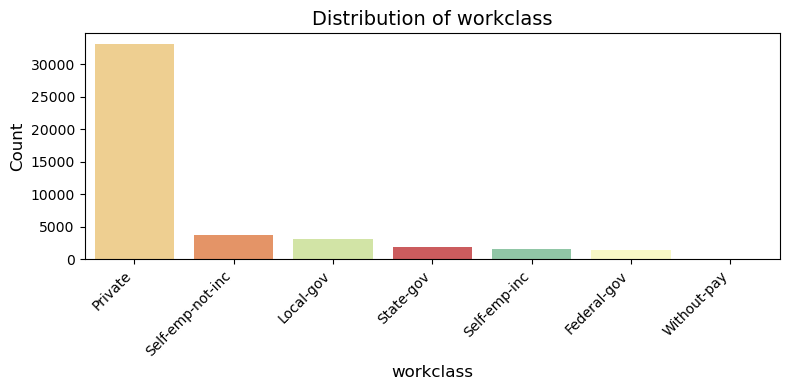

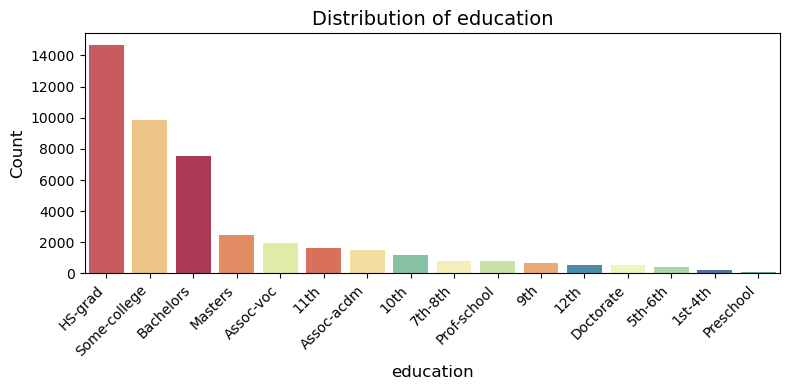

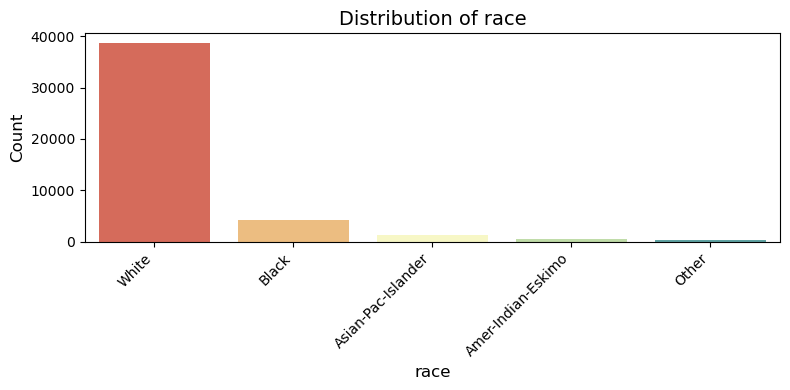

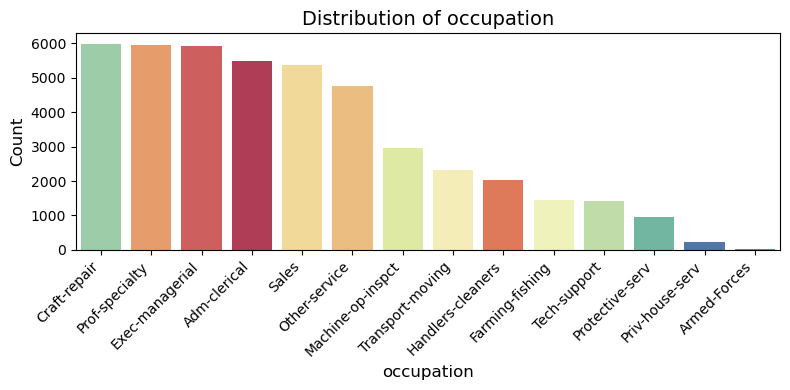

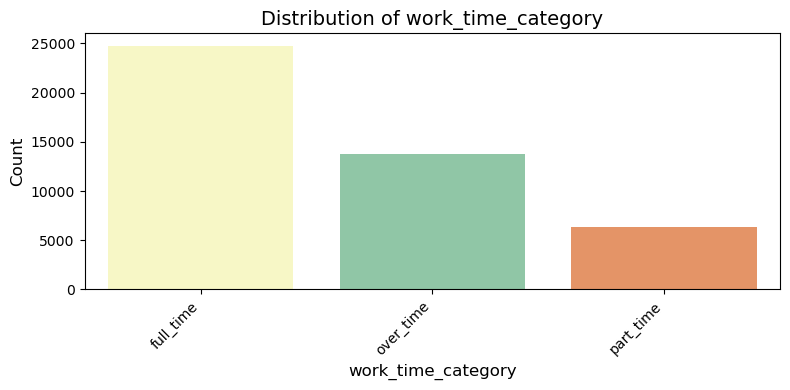

In [1359]:
# Visualize the most important categorical feartures for income class 
cat_cols = ["workclass", "education","race", "occupation", "work_time_category"]
# each categorical column and plot
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    order = df_census_income_ot[col].value_counts().index
    sns.countplot(data=df_census_income_ot, x=col, order=order, hue=col, legend=False, palette="Spectral")
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [1360]:
# Check some categorical values
cat_cols = ["occupation", "race", "native_country"]
for col in cat_cols:
    print(f"\nColumn: {col}")
    counts = df_census_income_ot[col].value_counts(dropna=False)  # counts
    proportions = df_census_income_ot[col].value_counts(normalize=True, dropna=False) * 100  # percentages
    
    summary = pd.DataFrame({
        "Count": counts,
        "Proportion (%)": proportions.round(2)
    })
    print(summary)


Column: occupation
                   Count  Proportion (%)
occupation                              
Craft-repair        5994           13.35
Prof-specialty      5966           13.29
Exec-managerial     5932           13.21
Adm-clerical        5503           12.25
Sales               5372           11.96
Other-service       4770           10.62
Machine-op-inspct   2956            6.58
Transport-moving    2307            5.14
Handlers-cleaners   2038            4.54
Farming-fishing     1447            3.22
Tech-support        1418            3.16
Protective-serv      967            2.15
Priv-house-serv      222            0.49
Armed-Forces          14            0.03

Column: race
                    Count  Proportion (%)
race                                     
White               38615           85.99
Black                4213            9.38
Asian-Pac-Islander   1292            2.88
Amer-Indian-Eskimo    434            0.97
Other                 352            0.78

Column: native_

In [1362]:
# We can group some values into one since they are very few.

# native_country
df_census_income_ot["native_country"] = df_census_income_ot["native_country"].apply(lambda x: "Non-US" if x != "US" else "US")

# race
df_census_income_ot["race"] = df_census_income_ot["race"].replace(["Amer-Indian-Eskimo", "Other"], "Others")

# occupation
df_census_income_ot["occupation"] = df_census_income_ot["occupation"].replace(["Protective-serv", "Priv-house-serv", "Armed-Forces"], "Others")


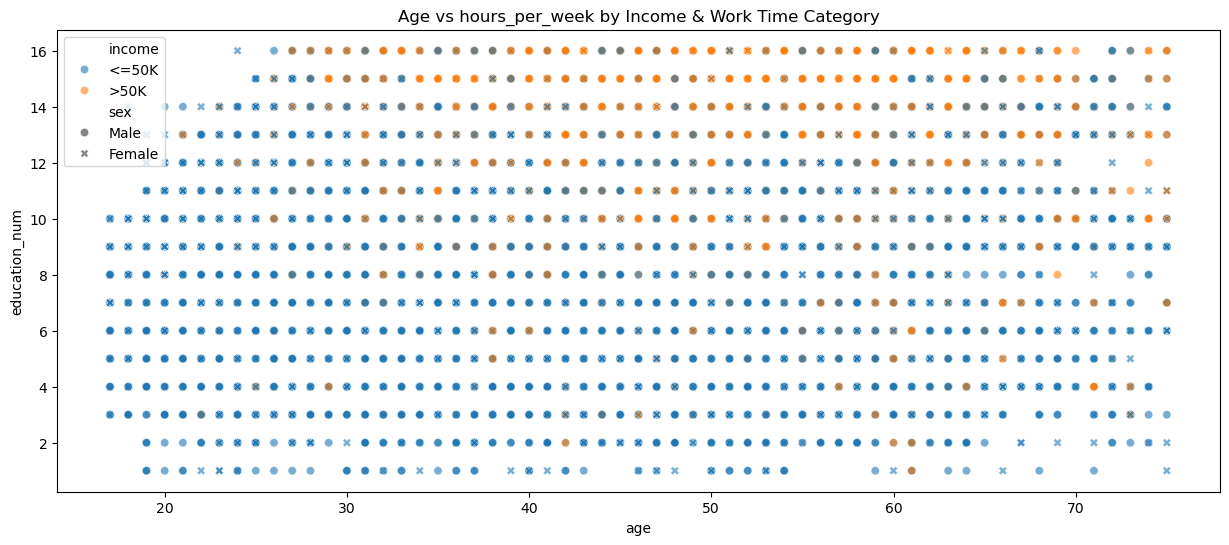

In [1363]:
plt.figure(figsize=(15,6))
sns.scatterplot(
    data=df_census_income_ot, x="age", y="education_num", alpha=0.6,
    hue="income",        # color by categorical
    style="sex"  # optional: shape by another categorical
)
plt.title("Age vs hours_per_week by Income & Work Time Category")
plt.show()

It looks like people who have higher education are making more money.

#### Sample Variance, Skewness, and Coefficient of Variation for Numeric Features

In [1364]:
# results dataframe
stats_df = pd.DataFrame(index=numeric_cols)

# Sample variance 
stats_df['Sample Variance'] = df_census_income_ot[numeric_cols].var(ddof=1)

# Skewness
stats_df['Skewness'] = df_census_income_ot[numeric_cols].skew()

# Coefficient of Variation (std / mean)
stats_df['Coefficient of Variation'] = df_census_income_ot[numeric_cols].std() / df_census_income_ot[numeric_cols].mean()

# Round for readability
stats_df = stats_df.round(4)

print("Sample Variance, Skewness, and Coefficient of Variation for Numeric Features:\n")
print(stats_df)

Sample Variance, Skewness, and Coefficient of Variation for Numeric Features:

                Sample Variance  Skewness  Coefficient of Variation
age                1.647014e+02    0.4179                    0.3351
fnlwgt             1.118585e+10    1.4481                    0.5570
education_num      6.467400e+00   -0.3036                    0.2512
capital_diff       5.657633e+07   11.7293                    7.4546
hours_per_week     1.426234e+02    0.3611                    0.2912


## Min-Max Sacling

We are keeping range [.01,1] min-max, since log normalization takes only positive values.

Min-Max deos not change shape or distribution of historgram.

Z-scale is a standardization method. It transforms data so that it has a mean (average) of 0 and a standard deviation of 1. 

We do not want 0 value, since we want to use log normalization method.


In [1365]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

df_scale = df_census_income_ot.copy()

numeric_cols = ["age", "fnlwgt", "education_num", "capital_gain","capital_loss","capital_diff", "hours_per_week"]

# Min-Max Scaling range [.01, 1]
scaler = MinMaxScaler(feature_range=(0.01, 1))
df_scale[numeric_cols] = scaler.fit_transform(df_scale[numeric_cols])

df_scale.describe() # summary statistics after Min-Max Sacling

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_diff
count,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000
mean,0.373617,0.128243,0.612292,0.020866,0.032487,0.414249,0.056775
std,0.219056,0.070895,0.167845,0.074230,0.102700,0.120644,0.071671
min,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000
25%,0.197759,0.079696,0.538000,0.010000,0.010000,0.403980,0.047161
50%,0.351379,0.120543,0.604000,0.010000,0.010000,0.403980,0.047161
75%,0.522069,0.160551,0.802000,0.010000,0.010000,0.454490,0.047161
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Log & Sqaure Root Normalization to squeeze any outliers

Note: We chose Log or SQRT, whichever gives the best results. Log method needs positive numbers. 

Z-scale works well when the feature is partially normal.

In [1366]:
# COPYING df_scale to df_norm BEFORE NORMALIZATION
df_norm = df_scale.copy()

numeric_cols_log = ["age", "hours_per_week"]
numeric_cols_sqrt = ["fnlwgt", "capital_gain" ,"capital_loss", "capital_diff"]

# Apply log1p to avoid log(0) errors
df_norm[numeric_cols_log] = df_norm[numeric_cols_log].apply(lambda x: np.log1p(x))

df_norm[numeric_cols_sqrt] = df_norm[numeric_cols_sqrt].apply(lambda x: np.sqrt(x))

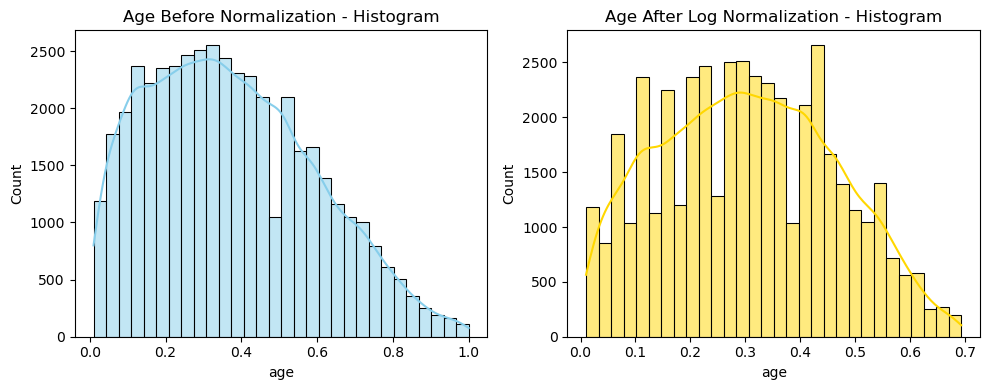

In [1367]:
# Hist before/after
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(df_scale["age"], kde=True, bins=30, color="skyblue", ax=axes[0])
axes[0].set_title("Age Before Normalization - Histogram")

sns.histplot(df_norm["age"], kde=True, bins=30, color="gold", ax=axes[1])
axes[1].set_title("Age After Log Normalization - Histogram")

plt.tight_layout()
plt.show()

We do not see any big improvment. We can use min-max scaling.

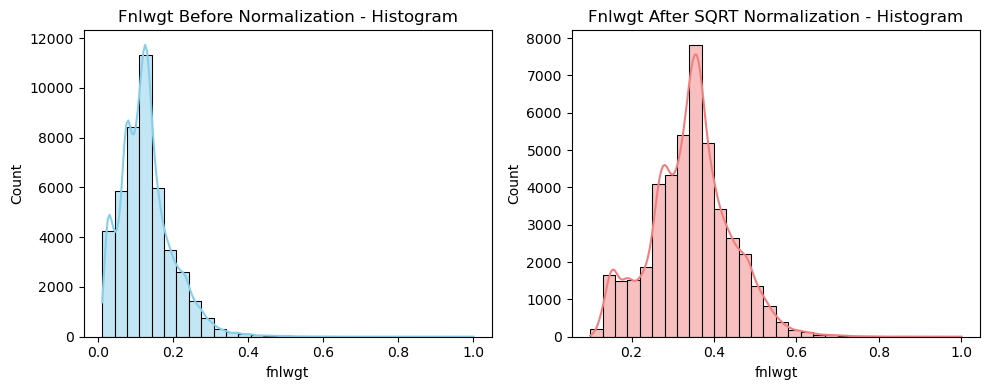

In [1368]:
# FNLWGT: side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Hist before/after
sns.histplot(df_scale["fnlwgt"], kde=True, bins=30, color="skyblue", ax=axes[0])
axes[0].set_title("Fnlwgt Before Normalization - Histogram")
sns.histplot(df_norm["fnlwgt"], kde=True, bins=30, color="lightcoral", ax=axes[1])
axes[1].set_title("Fnlwgt After SQRT Normalization - Histogram")

plt.tight_layout()
plt.show()


In [1369]:
df_norm.head() # After Log and SQRT Normalization

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,capital_diff,work_time_category
0,0.326074,State-gov,0.230036,Bachelors,0.802,Never-married,Adm-clerical,Not-in-family,White,Male,0.177547,0.1,0.339311,US,<=50K,0.260530,full_time
1,0.453160,Self-emp-not-inc,0.238330,Bachelors,0.802,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.100000,0.1,0.123301,US,<=50K,0.217166,part_time
2,0.313677,Private,0.381455,HS-grad,0.538,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.100000,0.1,0.339311,US,<=50K,0.217166,full_time
3,0.485189,Private,0.397862,11th,0.406,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.100000,0.1,0.339311,US,<=50K,0.217166,full_time
4,0.180452,Private,0.477282,Bachelors,0.802,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.100000,0.1,0.339311,Non-US,<=50K,0.217166,full_time


In [1370]:
df_norm.describe() # After Log and SQRT Normalization

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_diff
count,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000,44906.000000
mean,0.304934,0.344565,0.612292,0.118501,0.128080,0.342958,0.228404
std,0.157801,0.097561,0.167845,0.082607,0.126819,0.085570,0.067876
min,0.009950,0.100000,0.010000,0.100000,0.100000,0.009950,0.100000
25%,0.180452,0.282304,0.538000,0.100000,0.100000,0.339311,0.217166
50%,0.301126,0.347193,0.604000,0.100000,0.100000,0.339311,0.217166
75%,0.420071,0.400688,0.802000,0.100000,0.100000,0.374655,0.217166
max,0.693147,1.000000,1.000000,1.000000,1.000000,0.693147,1.000000


## Covariance

Covariance measures how two variables change together. When one increases, the other tends to increase and vice-versa. 

Covariance is not standardized, so the magnitude depends on the units of the variables.

**Hence, We calculate Covariance on raw data, we will see much larger values that reflect the original units**

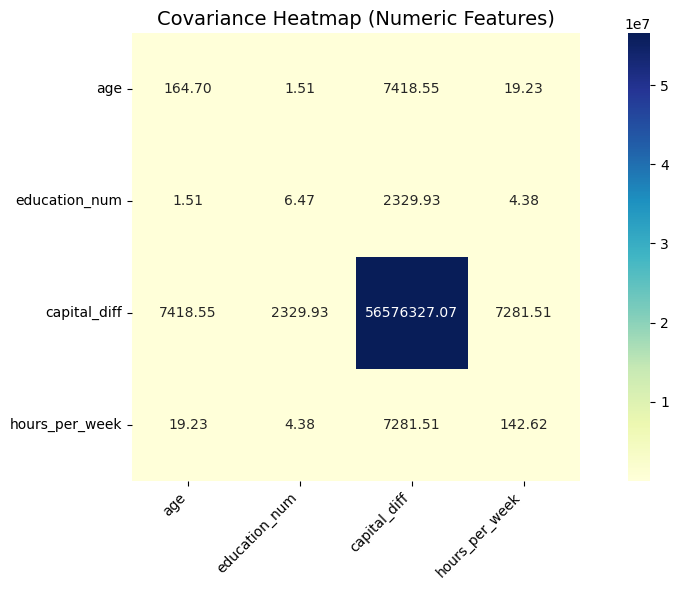

In [1372]:
# Compute covariance matrix
numeric_cols_cov = ["age", "education_num", "capital_diff", "hours_per_week"]

cov_matrix = df_census_income_ot[numeric_cols_cov].cov()

# Plot heatmap for covariance
plt.figure(figsize=(10, 6))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="YlGnBu", cbar=True, square=True)
plt.title("Covariance Heatmap (Numeric Features)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [1373]:
cov_matrix # covariance matrix

,age,education_num,capital_diff,hours_per_week
age,164.701445,1.511470,7.418554e+03,19.231498
education_num,1.511470,6.467368,2.329931e+03,4.378987
capital_diff,7418.553694,2329.931323,5.657633e+07,7281.511913
hours_per_week,19.231498,4.378987,7.281512e+03,142.623375


age & hours_per_week = 19.23: older people work slightly more hours.

education_num & capital_diff are high, means higher education levels get higher capital gains.

capital_diff & hours_per_week, it looks like people with more capital gains work more hours.

Very large covariance values are due to large scales of variables like capital_diff.

## Pearson correlation coefficient 

Measures the strength and direction of a linear relationship between variables, scaled between -1 and 1.
We will calcualte correlation coefficient on scaled dataframe.

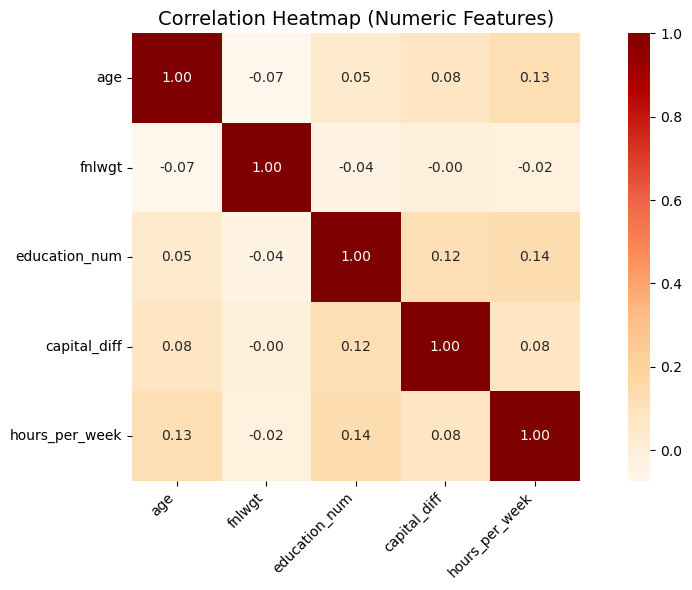

In [1374]:
# Compute correlation matrix

numeric_cols_cor = ["age", "fnlwgt", "education_num", "capital_diff", "hours_per_week"]

corr_matrix = df_scale[numeric_cols_cor].corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="OrRd", cbar=True, square=True)
plt.title("Correlation Heatmap (Numeric Features)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**All correlations are well below 0.6, so no obvious multicollinearity from the correlation matrix.**

## Spearman correlation coefficient 

Spearman correlation measures the strength and direction of a monotonic relationship (not just linear).
It works on ranks, so it’s less sensitive to outliers.

We are using Label Encoding, since Spearman correlation needs numeric inputs to compute ranks.

One-hot encoding is not used here because that would produce many binary columns, making the Spearman matrix complex.

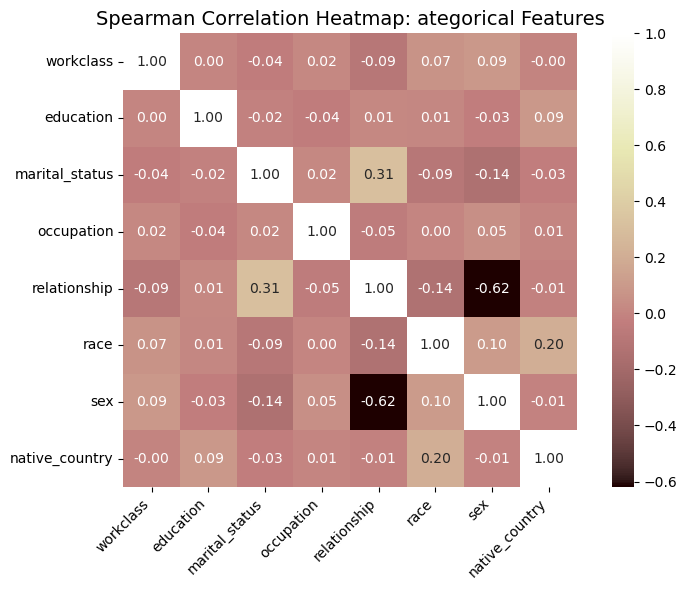

In [1375]:
from sklearn.preprocessing import LabelEncoder

# copy original DataFrame
df_spearman = df_scale.copy()

# Categorical columns to check (no income here)
categorical_cols = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]

# Encode categorical variables
le = LabelEncoder()
for col in categorical_cols:
    df_spearman[col] = le.fit_transform(df_spearman[col])

# Calculate Spearman correlation matrix
spearman_corr = df_spearman[categorical_cols].corr(method='spearman')

# Plot heatmap for categorical features only
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="pink", cbar=True, square=True)
plt.title("Spearman Correlation Heatmap: ategorical Features", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Most correlations are 0. It means, categorical features are largely independent

relationship vs sex = -0.62. It is very strong inverse relationship, “Husband” strongly linked to “Male,” “Wife” to “Female”

In [1376]:
# create new column income_0_1; 0 for "<=50" 1 and for ">50K" and
df_norm["income_0_1"] = df_census_income["income"].apply(lambda x: 1 if x == ">50K" else 0)

df_scale["income_0_1"] = df_census_income["income"].apply(lambda x: 1 if x == ">50K" else 0)

df_norm.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,capital_diff,work_time_category,income_0_1
0,0.326074,State-gov,0.230036,Bachelors,0.802,Never-married,Adm-clerical,Not-in-family,White,Male,0.177547,0.1,0.339311,US,<=50K,0.260530,full_time,0
1,0.453160,Self-emp-not-inc,0.238330,Bachelors,0.802,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.100000,0.1,0.123301,US,<=50K,0.217166,part_time,0
2,0.313677,Private,0.381455,HS-grad,0.538,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.100000,0.1,0.339311,US,<=50K,0.217166,full_time,0
3,0.485189,Private,0.397862,11th,0.406,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.100000,0.1,0.339311,US,<=50K,0.217166,full_time,0
4,0.180452,Private,0.477282,Bachelors,0.802,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.100000,0.1,0.339311,Non-US,<=50K,0.217166,full_time,0


## t-Test

- Null Hypothesis (H₀): The average age for people earning <=50K is the same as for those earning >50K
- Alternative Hypothesis (H₁): The average age differs between the two income groups.



In [1377]:
# Group standard deviations for age
std_by_income = df_scale.groupby('income')['age'].std()
print(std_by_income)

income
<=50K    0.224007
>50K     0.171617
Name: age, dtype: float64


We are checking the equal varaince of two group using "doubling rubic".

***If the larger SD is less than double the smaller SD, we assume equal variances.
So, we assume it is equal variance.***

In [1378]:
from scipy.stats import ttest_ind

# income_0_1: 0 <=50K and 1 >50 

g0 = df_scale.loc[df_norm['income_0_1'] == 0, 'age']
g1 = df_scale.loc[df_norm['income_0_1'] == 1, 'age']

t_stat, p_val = ttest_ind(g0, g1, equal_var=True) # Student's t-test (pooled variance)

# Degrees of freedom
df_val = len(g0) + len(g1) - 2

# Results
print(f"Group 0 (<=50K) Mean: {g0.mean():.4f}, Std: {g0.std(ddof=1):.4f}, n={len(g0)}")
print(f"Group 1 (>50K)  Mean: {g1.mean():.4f}, Std: {g1.std(ddof=1):.4f}, n={len(g1)}")
print(f"T-value: {t_stat:.4f}")
print(f"Degrees of Freedom: {df_val}")
print(f"P-value: {p_val}")


Group 0 (<=50K) Mean: 0.3424, Std: 0.2240, n=33752
Group 1 (>50K)  Mean: 0.4682, Std: 0.1716, n=11154
T-value: -54.2904
Degrees of Freedom: 44904
P-value: 0.0


T-value = -54.2904, Large t-value shows a big difference in means relative to variation.
P-value =  0 is so samll that test is Statistically significant at any reasonable alpha level (e.g., 0.05, 0.01).

***We reject the null hypothesis. There’s very strong evidence that average age differs between income groups***

## One-Way ANOVA

We want to determine whether the average normalized age differs significantly among individuals in different work time categories (part_time, full_time, overtime).

Null Hypothesis (H₀): 𝜇_part_time = 𝜇_full_time = 𝜇_over_time
 - The mean age is the same across all work time categories.

Alternative Hypothesis (H₁):
 - At least one work time category has a different mean age.

***Since it is  One-Way ANOVA all Types-I, II, and III of sum of squares give the same result.***


In [1379]:
df_scale.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,capital_diff,work_time_category,income_0_1
0,0.385517,State-gov,0.052917,Bachelors,0.802,Never-married,Adm-clerical,Not-in-family,White,Male,0.031523,0.01,0.403980,US,<=50K,0.067876,full_time,0
1,0.573276,Self-emp-not-inc,0.056801,Bachelors,0.802,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.010000,0.01,0.131224,US,<=50K,0.047161,part_time,0
2,0.368448,Private,0.145508,HS-grad,0.538,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.010000,0.01,0.403980,US,<=50K,0.047161,full_time,0
3,0.624483,Private,0.158294,11th,0.406,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.010000,0.01,0.403980,US,<=50K,0.047161,full_time,0
4,0.197759,Private,0.227798,Bachelors,0.802,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.010000,0.01,0.403980,Non-US,<=50K,0.047161,full_time,0


In [1380]:
# Equal variances (homoscedasticity) across all groups checking
# the spread (variance) of the dependent variable- age must be roughly equal in each group (part_time, full_time, overtime).
std_by_group = df_scale.groupby("work_time_category")["age"].std(ddof=1) # Standard deviation
print(std_by_group)

work_time_category
part_time    0.293504
full_time    0.209522
over_time    0.185470
Name: age, dtype: float64


Doubling rule says equal variance assumption is reasonable.

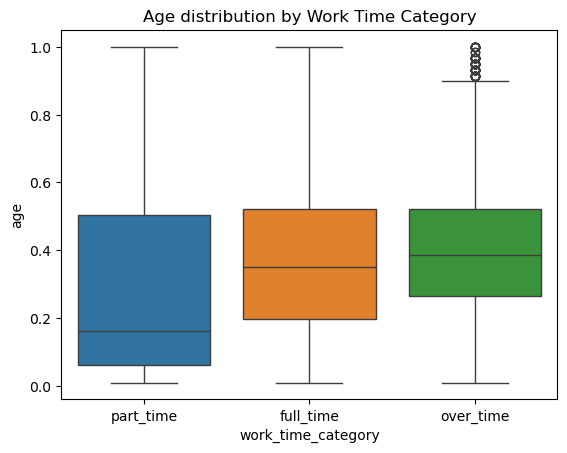

In [1381]:
# We can visualize the data spread using box plot 
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]  # Blue, Orange, Green
sns.boxplot( x="work_time_category", y="age", hue="work_time_category", data=df_scale, palette=["#1f77b4", "#ff7f0e", "#2ca02c"], legend=False)
plt.title("Age distribution by Work Time Category")
plt.show()

In [1382]:
from scipy.stats import f_oneway

# Prepare data
groups = [df_scale.loc[df_scale["work_time_category"] == cat, "age"] 
          for cat in df_scale["work_time_category"].unique()]

# One-WANOVA calculation
f_stat, p_value = f_oneway(*groups)

# Calculate R² and Adjusted R²
n = len(df_scale)
k = df_scale["work_time_category"].nunique()

grand_mean = df_scale["age"].mean()

# Between-group sum of squares
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
# Total sum of squares
ss_total = sum((x - grand_mean)**2 for x in df_scale["age"])

# R²
r_squared = ss_between / ss_total

# Adjusted R²
adj_r_squared = 1 - (1 - r_squared) * (n - 1) / (n - k)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"R²: {r_squared:.4f}")
print(f"Adjusted R²: {adj_r_squared:.4f}")


F-statistic: 475.7174
P-value: 0.000000
R²: 0.0207
Adjusted R²: 0.0207


F-statistic = 475.7174 is a very large value, and P-value < 0.000001 is small, Statistically significant at any conventional aplha value. (e.g., 0.05).

***So, We reject Null Hypothesis (H₀) and conclude at least one group’s mean age is different.***

R² = 0.0207; Only ~2.07% of the variance in the dependent variable is explained by the group differences. Even though the result is statistically significant, the effect size is small

Adjusted R² = 0.0207; Almost the same as R², since we have only have 3 groups.


## Regression and Classification

## Linear Regression
- Predict age based on work-related, demographic, and income features

In [1384]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# Feature preparation
numeric_cols = ["capital_diff","hours_per_week"]
categorical_cols = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex"]

# We will use normalized dataframe 

# One-hot encode categorical variables (drop_first=True to avoid dummy trap)
df_encoded = pd.get_dummies(df_norm[categorical_cols], drop_first=True) 

# Combine numeric predictors (excluding target) with encoded categoricals
X = pd.concat([df_norm[numeric_cols], df_encoded], axis=1) 
y = df_norm["age"]

# split dataset into train and test
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.25, random_state=0)


# Fit the model
lmr = LinearRegression().fit(X_train, y_train)

# Predictions & evaluation
y_pred = lmr.predict(X_test)

# Coefficients

numeric_features = X.select_dtypes(include=[np.number]).columns

coeff_df = pd.DataFrame({
    "Feature": numeric_features,
    "Coefficient": lmr.coef_[:len(numeric_features)]
}).sort_values(by="Coefficient", ascending=False)

# R-Squared 
r2_lr = lmr.score(X_test,y_test)

mse_lr = mean_squared_error(y_test, y_pred)

# Root Mean Squared Error (RMSE) is the square root of MSE
rmse_lr = np.sqrt(mse_lr)

print("\n*** Linear Regression ***")

print("\nR²:", round(r2_lr, 4))
print("RMSE:", round(rmse_lr, 4))

print("\nNumeric Feature's Coefficients:\n", coeff_df) # Showing only coefficients for Numeric IVs.
print("\nIntercept:", lmr.intercept_)


*** Linear Regression ***

R²: 0.429
RMSE: 0.1188

Numeric Feature's Coefficients:
           Feature  Coefficient
0    capital_diff     0.078114
1  hours_per_week    -0.051908

Intercept: 0.48599370226944705


R² = 0.429, This means  model explains about 42.9% of the variance in the target variable.

An RMSE of 0.1188 means that on average, predictions are about 11.9% off from the actual values.

Intercept = 0.4859, This is the predicted value of the target (y) when all predictors are 0.


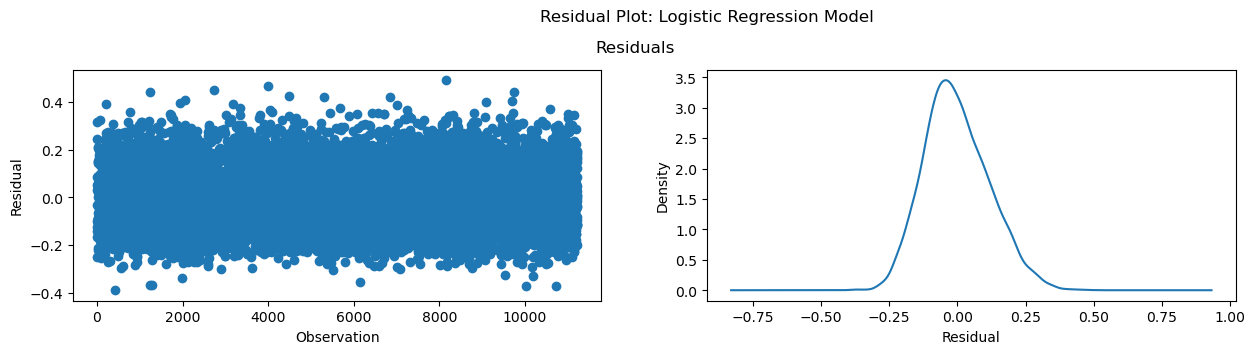

In [1385]:
# Linear regression: visualize the residuals
from ml_utils.regression import plot_residuals
plot_residuals(y_test, y_pred)
plt.title( "Residual Plot: Logistic Regression Model", loc="center",  pad=35, x=0.0)
plt.show()

Most points hover above and below the horizontal mean-zero line, which is good, and handful of points lie far from zero.

Both sides have fairly heavy tails, indicating occasional large errors, it is consistent with the outliers we saw in the scatter.

We tried our best to predict the Age. We need more features like weight, height or other health attributes to predict precise age. 
This dataset is more likey for classification or clustering.

## Classificaiotn 

***We will apply logistics regression to classify if an observation make >50K or <=50K yearly.***

In [1386]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score


# Select features and target
numeric_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
categorical_cols = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]

# One-hot encode categoricals
df_encoded = pd.get_dummies(df_scale[categorical_cols], drop_first=True)

# Combine numeric + categorical
X = pd.concat([df_scale[numeric_cols], df_encoded], axis=1)
y = df_scale["income_0_1"] # 0 is <=50K ; 1 is >50K

# Split dataset test and train
# stratify: imbalanced data, to make sure that both the training and testing sets preserve the ratio of true and false 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

# Fit logistic regression model
lmr_log = LogisticRegression(max_iter=1000, random_state=0).fit(X_train, y_train)
lmr_log.fit(X_train, y_train)

# Predictions
y_pred = lmr_log.predict(X_test)

# Model evaluation
accuracy_log = accuracy_score(y_test, y_pred)

# score_log= lmr_log.score(X_test, y_test)  # same as accuracy for classification

print("*** Logistic Regression ***" )
print(f"\nAccuracy: {accuracy_log:.4f}")



*** Logistic Regression ***

Accuracy: 0.8417


**Accuracy score, our model is correctly predicting the target about 84.17% of the time on our test data.**

*** Confusion Matrix ***



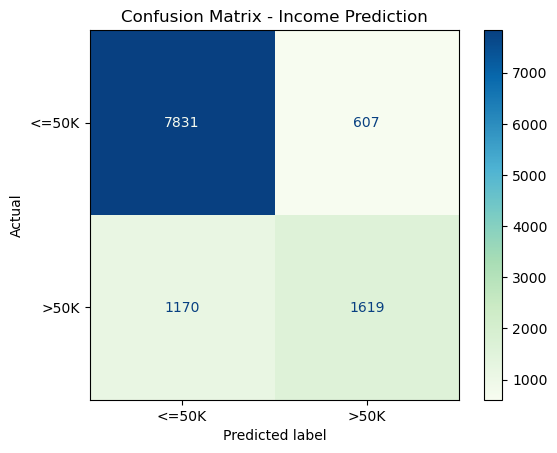

*** Classification Report ***

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      8438
           1       0.73      0.58      0.65      2789

    accuracy                           0.84     11227
   macro avg       0.80      0.75      0.77     11227
weighted avg       0.83      0.84      0.84     11227



In [1387]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from ml_utils.classification import confusion_matrix_visual

# Get confusion matrix
# confusion_matrix_visual(y_test, y_pred, ["<=50K", ">50K"])

# Convert integers to strings before plotting
mapping = {0: "<=50K", 1: ">50K"}
y_test_labels = y_test.map(mapping)
y_pred_labels = pd.Series(y_pred).map(mapping)

cm = confusion_matrix(y_test_labels, y_pred_labels, labels=["<=50K", ">50K"])

# Confusion Matrix
print("*** Confusion Matrix ***\n")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
disp.plot(cmap="GnBu", values_format='d')

plt.title("Confusion Matrix - Income Prediction")
plt.ylabel("Actual")
plt.show()

# Classification report
print("*** Classification Report ***\n")
print(classification_report(y_test,y_pred))


This model strongly predicts low-income individuals. Struggles with high-income detection, mainly because of class imbalance and possible overlap in feature patterns.

Precision: 0.80; Recall: 0.75; F1-score: 0.77

Precision and recall provide a better way of evaluating model performance in the face of a class imbalance.

All values around 0.83–0.84 because <=50K dominates the dataset.

Type-I error (False Positive) and  Type-II error (False Negative) are very low.

We are able to maximize both Sensitivity-true positive and Specificity-true negative.

<Axes: title={'center': 'ROC curve'}, xlabel='False Positive Rate (FPR)', ylabel='True Positive Rate (TPR)'>

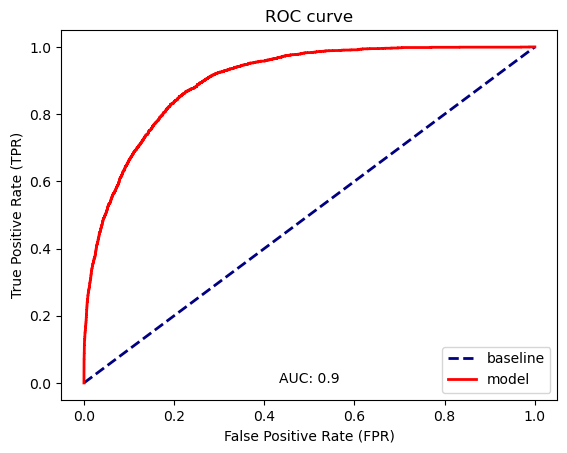

In [1388]:
from ml_utils.classification import plot_roc
from sklearn.metrics import roc_curve, roc_auc_score

plot_roc(y_test, lmr_log.predict_proba(X_test)[:,1])

**AUC is 0.90, and it is very good model.**

<Axes: title={'center': 'Precision-recall curve\nAP: 0.76 | AUC: 0.76'}, xlabel='Recall', ylabel='Precision'>

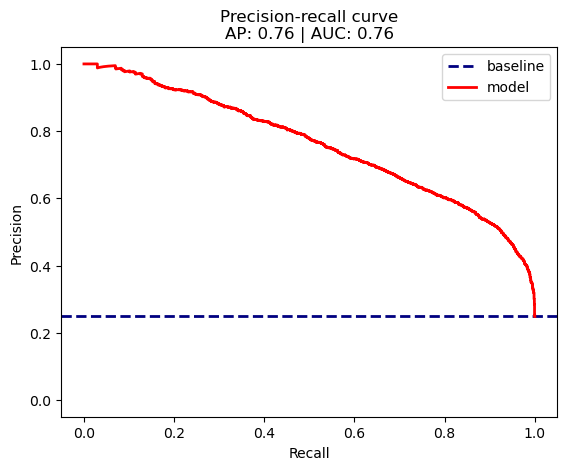

In [1389]:
from ml_utils.classification import plot_pr_curve
plot_pr_curve(y_test, lmr_log.predict_proba(X_test)[:,1])

AP (Average Precision) = 0.76, our model maintains 76 % precision across different recall thresholds.

Our dataseit is imbalance. It is approximately 75% for <=50K and 25% for >50K 

## Clustering- Advanced Analysis Techniques

Clustering in machine learning is an unsupervised learning technique used to group unlabeled data points based on their similarities. 

**K-Means: Separate the dataset into two clusters (k = 2) based on features like age, education, income, marital_status  etc., without telling the model the actual sex labels.**

We are not creating Income Clusters, since we did this classification in Regression Model, So let's try new model with same dataset.

In [1390]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import fowlkes_mallows_score
from sklearn.model_selection import train_test_split

# Features selections
numeric_cols = [ "age", "education_num"] # hours_per_week
categorical_cols =[ "marital_status"] # "occupation", "race", "income", "workclass","race" 

# One-hot encode categoricals
df_encoded = pd.get_dummies(df_scale[categorical_cols], drop_first=True)

# Combine numeric + encoded categorical features
X_full = pd.concat([df_scale[numeric_cols], df_encoded], axis=1)

# "Sex" is a Target Feature here, It is used for for FMI evaluation.
y_full = df_scale[ "sex"]

# Train/Test split
# Stratified: since our dataset is imbalanced.
X_train_km, X_test_km, y_train_km, y_test_km = train_test_split(
    X_full, y_full, test_size=0.25, random_state=0, stratify=y_full
)

# K-Means Pipeline 
n_clusters = y_full.nunique() # get Sex unique values 
km_pipeline = make_pipeline(
    KMeans(n_clusters=n_clusters, random_state=0, n_init=10)  # Dataset is already Min-Max Scaled.
)

# Fit on training data
km_pipeline.fit(X_train_km)

# Predict clusters
cluster_labels = km_pipeline.predict(X_test_km)

fmi_score = fowlkes_mallows_score(y_test_km, cluster_labels)
print("*** K-Means Cluster ***")
print(f"\nFowlkes–Mallows Index: {fmi_score:.4f}")


*** K-Means Cluster ***

Fowlkes–Mallows Index: 0.6052


The clusters are doing better than random grouping, Some overlap in feature values between males and females.

In [1391]:
pd.Series(cluster_labels).value_counts() # training dataset

0    5893
1    5334
Name: count, dtype: int64

K-Means is unsupervised and we do not know the actual sex labels, it just groups by feature similarity.

In [1394]:
# extract the cluster centers
scaled_centers = km_pipeline.named_steps['kmeans'].cluster_centers_

# dataframe with features as columns
df_centers = pd.DataFrame(scaled_centers, columns=X_train_km.columns)

# 3. Transpose
df_centers = df_centers.T

print("*** Cluster centers ***")
df_centers

*** Cluster centers ***


,0,1
age,3.083664e-01,4.459548e-01
education_num,5.998463e-01,6.254634e-01
marital_status_Married-AF-spouse,1.326113e-03,-2.059984e-17
marital_status_Married-civ-spouse,-1.182388e-14,1.000000e+00
marital_status_Married-spouse-absent,2.259918e-02,-5.499073e-16
marital_status_Never-married,6.047077e-01,8.382184e-15
marital_status_Separated,5.873577e-02,7.285839e-16
marital_status_Widowed,4.796110e-02,-4.822531e-16


Explained variance by PC1 & PC2: 0.648, 0.157


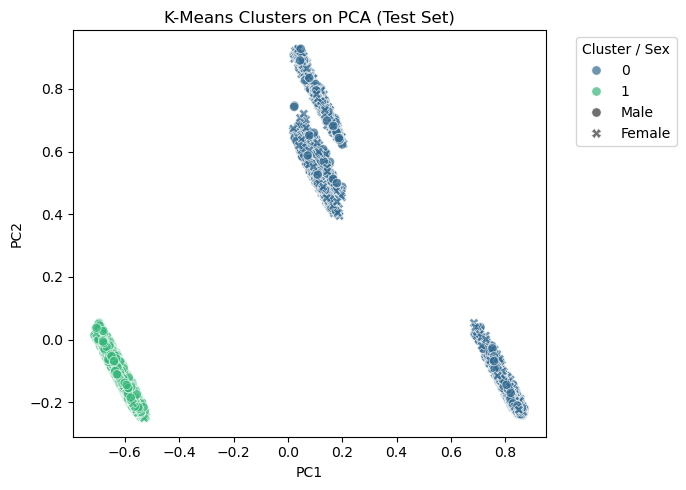

In [1395]:
from sklearn.decomposition import PCA

# PCA projection of the TEST set
pca = PCA(n_components=2, random_state=0)
X_test_pca = pca.fit_transform(X_test_km)

print(f"Explained variance by PC1 & PC2: {pca.explained_variance_ratio_[0]:.3f}, {pca.explained_variance_ratio_[1]:.3f}")

# Scatter: color by cluster, shape by true sex
plt.figure(figsize=(7,5))
sns.scatterplot(
    x=X_test_pca[:, 0], y=X_test_pca[:, 1],
    hue=cluster_labels, style=y_test_km.values,
    alpha=0.7, s=45, palette="viridis"
)
plt.title("K-Means Clusters on PCA (Test Set)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(title="Cluster / Sex", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

PC1 + PC2 together explain 64.8% + 15.7% = 80.5% of the variance.

***That’s quite good, PC1 and PC2 preserves about 80% of the information from the original multi-dimensional dataset.***